# 03 · Clinical notes EDA
Quality audit, length distributions, class-specific vocabulary (TF-IDF) and keyword prevalence.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

In [2]:
notes = pd.read_csv(ROOT / 'data/raw/clinical_notes/clinical_notes.csv')
print('raw notes', len(notes), '| exact duplicates', notes.duplicated(['patient_id', 'visit_date', 'note_text']).sum(),
      '| empty', notes.note_text.isna().sum())
for t in notes.note_text.dropna().sample(3, random_state=0): print('-', t, '\n')

raw notes 514 | exact duplicates 6 | empty 3
- 62-year-old male seen for memory lapses noticed by pt and spouse over the past year. Subtle episodic memory weakness, otherwise intact. Some difficulty with IADLs; spouse now manages bills. Retired teacher. No focal neuro deficits on exam. Walks 30 min daily. Lives with spouse. Impression: amnestic MCI, likely due to AD. Plan: MRI brain and neuropsych referral. 

- 78-year-old female seen for progressive memory decline over 18-24 months. Episodic memory impaired; executive function borderline. Some difficulty with IADLs; spouse now manages bills. Gait normal. Lives with spouse. Findings consistent with mild cognitive change. 

- 74-year-old male seen for memory lapses noticed by patient and spouse over the past year. Mild delayed recall deficit on word list; recognition preserved. Minimal IADL change. Former smoker, quit 20 yrs ago. Walks 30 min daily. Lives alone, daughter nearby. Impression: possible early MCI. Plan: repeat testing in 12

In [3]:
from ad_mm.preprocessing.text import clean_note
print(clean_note(notes.note_text.dropna().iloc[0]))

<num>-year-old female seen for patient complains of misplacing objects and word-finding pauses. subjective complaint; no objective deficit on screening. independent; works part-time and drives. sleep <num>-<num> hours per night. hearing aids bilaterally. lives alone, daughter nearby. no evidence of neurocognitive disorder.


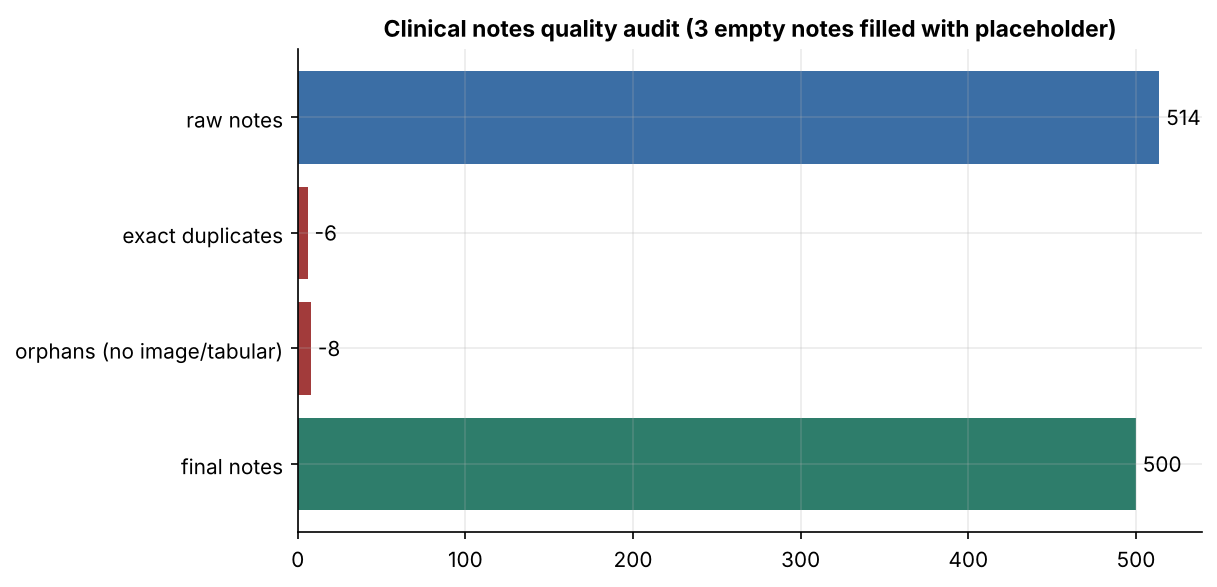

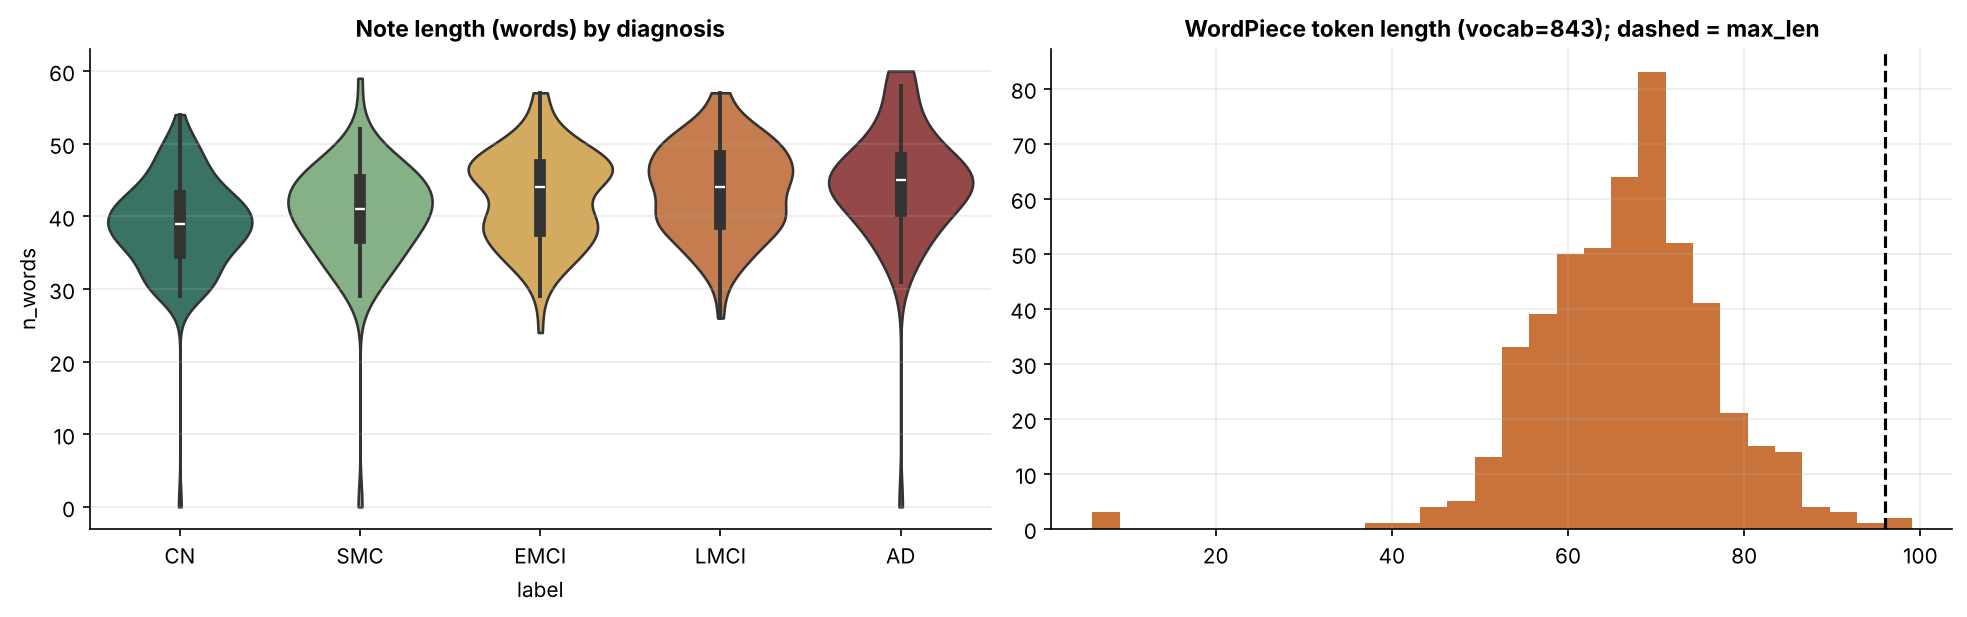

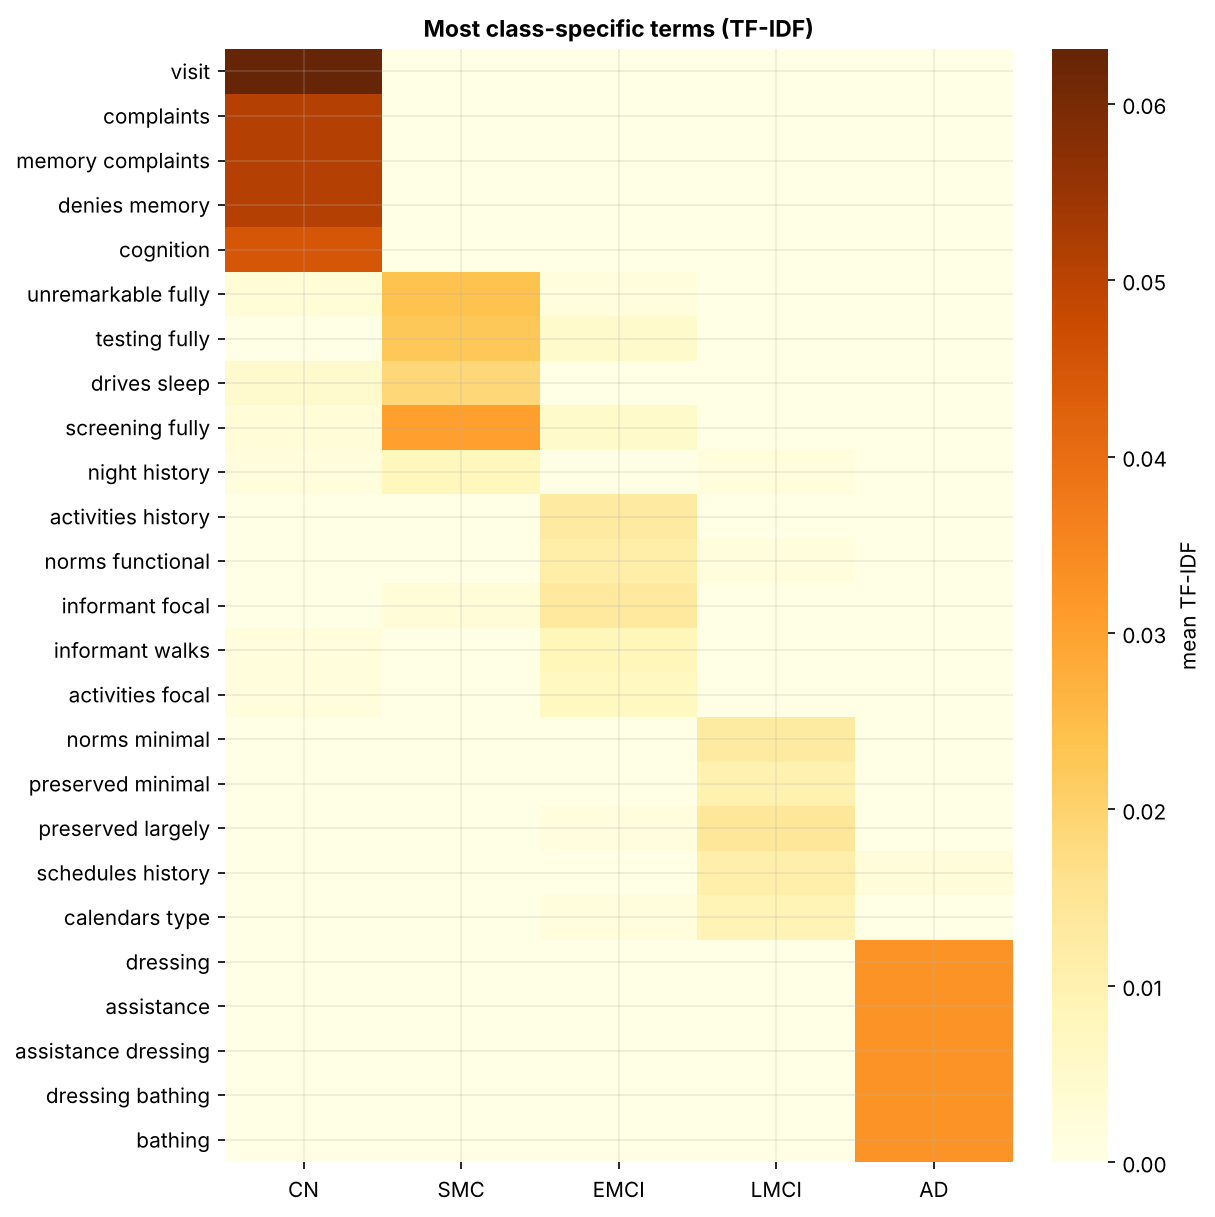

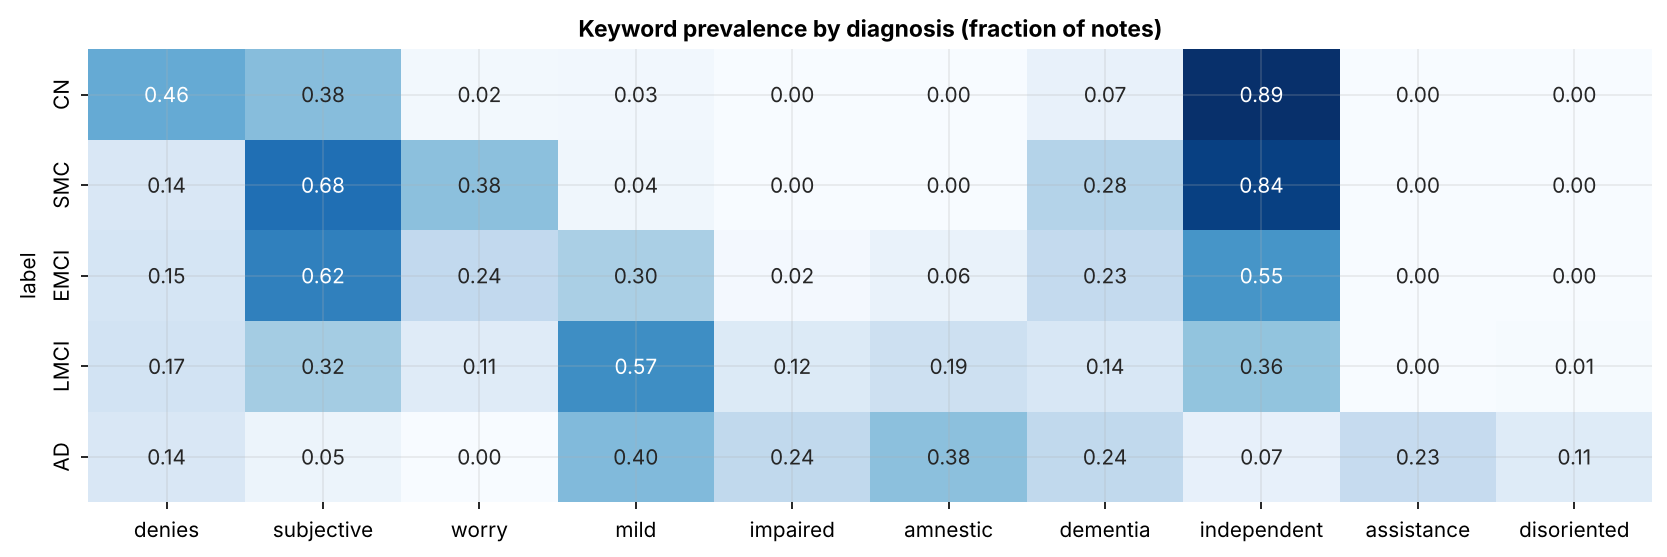

In [4]:
for n in ['10_txt_quality_audit', '11_txt_length_distributions', '12_txt_tfidf_terms_by_class', '13_txt_keyword_prevalence']: show(n)